In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the CSV from the project's data folder
csv_path = Path("data\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = pd.read_csv(csv_path)

print("Shape:", df.shape)
display(df.head())

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values before cleaning:")
print(df.isna().sum().sort_values(ascending=False).head(10))

print("\nChurn counts:")
print(df["Churn"].value_counts())

print("\nChurn proportions:")
print(df["Churn"].value_counts(normalize=True).round(3))


<>:8: SyntaxWarning: invalid escape sequence '\W'
<>:8: SyntaxWarning: invalid escape sequence '\W'
C:\Users\Ramesh\AppData\Local\Temp\ipykernel_30216\2582744886.py:8: SyntaxWarning: invalid escape sequence '\W'
  csv_path = Path("data\WA_Fn-UseC_-Telco-Customer-Churn.csv")


ModuleNotFoundError: No module named 'seaborn'

In [2]:
print("Notebook is working")

Notebook is working


In [3]:
from pathlib import Path
import pandas as pd

filename = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

possible_paths = [
    Path("data") / filename,
    Path("churn-prediction-app") / "data" / filename,
    Path("../data") / filename,
]

csv_path = next((path for path in possible_paths if path.exists()), None)

print("Notebook is running from:", Path.cwd())

if csv_path is None:
    print("Could not find the CSV. Checked:")
    for path in possible_paths:
        print(" -", path.resolve())
else:
    print("Using CSV:", csv_path.resolve())
    df = pd.read_csv(csv_path)
    print("Shape:", df.shape)
    display(df.head())

Notebook is running from: c:\Users\Ramesh\OneDrive\Pictures\Desktop\Documents\Churn Prediction ML App\churn-prediction-app\notebooks
Using CSV: C:\Users\Ramesh\OneDrive\Pictures\Desktop\Documents\Churn Prediction ML App\churn-prediction-app\data\WA_Fn-UseC_-Telco-Customer-Churn.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Column data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False).head(10))

print("\nChurn counts:")
print(df["Churn"].value_counts())

print("\nChurn proportions:")
print(df["Churn"].value_counts(normalize=True).round(3))

Column data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Missing values:
customerID         0
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
OnlineSecurity     0
dtype: int64

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn proportions:
Churn
No     0.735
Yes    0.265
Name: proportion

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing TotalCharges after conversion:", df["TotalCharges"].isna().sum())
display(df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "TotalCharges"]])

Missing TotalCharges after conversion: 11


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,NaN
753,3115-CZMZD,0,NaN
936,5709-LVOEQ,0,NaN
1082,4367-NUYAO,0,NaN
1340,1371-DWPAZ,0,NaN
3331,7644-OMVMY,0,NaN
3826,3213-VVOLG,0,NaN
4380,2520-SGTTA,0,NaN
5218,2923-ARZLG,0,NaN
6670,4075-WKNIU,0,NaN


In [6]:
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("Tenure values for those rows:")
print(df.loc[df["TotalCharges"].isna(), "tenure"].value_counts())

Missing TotalCharges: 11
Tenure values for those rows:
tenure
0    11
Name: count, dtype: int64


In [7]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Yes, dtype: float64


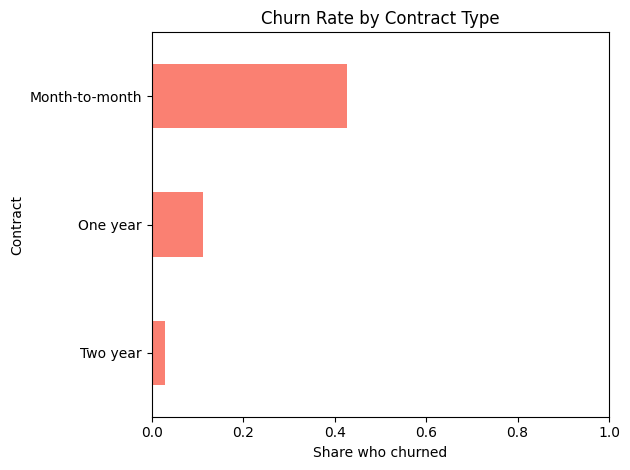

In [8]:
# Calculate the share of customers who churn in each contract group
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
)["Yes"].sort_values(ascending=False)

print(contract_churn.round(3))

contract_churn.sort_values().plot(
    kind="barh",
    color="salmon",
    title="Churn Rate by Contract Type"
)
plt.xlabel("Share who churned")
plt.ylabel("Contract")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

In [9]:
import seaborn as sns

ModuleNotFoundError: No module named 'seaborn'

In [ ]:

sns.boxplot(data=df, x="Churn", y="tenure", hue="Churn", legend=False)
plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")
plt.tight_layout()
plt.show()

NameError: name 'sns' is not defined

In [11]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn", legend=False)
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly charges")
plt.tight_layout()
plt.show()

NameError: name 'sns' is not defined

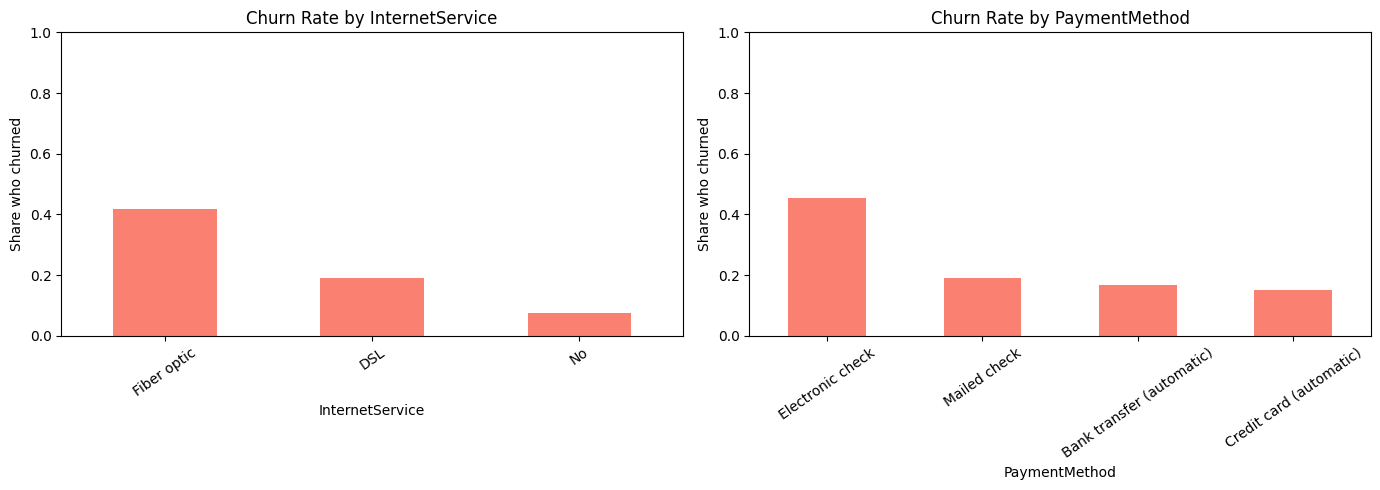

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(axes, ["InternetService", "PaymentMethod"]):
    rates = (
        pd.crosstab(df[column], df["Churn"], normalize="index")["Yes"]
        .sort_values(ascending=False)
    )
    rates.plot(kind="bar", ax=ax, color="salmon")
    ax.set_title(f"Churn Rate by {column}")
    ax.set_ylabel("Share who churned")
    ax.set_xlabel(column)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Remove customerID: it's an identifier, not a useful customer behavior feature.
X = df.drop(columns=["Churn", "customerID"])

# Convert the target into numbers: No = 0, Yes = 1.
y = df["Churn"].map({"No": 0, "Yes": 1})

# Split before fitting any imputers, scaler, or encoder.
# stratify=y keeps the churn share similar in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Identify columns by their data type.
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric columns:", numeric_features)
print("Categorical columns:", categorical_features)
print("\nTraining rows:", len(X_train))
print("Test rows:", len(X_test))
print("\nTraining churn share:")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print("\nTest churn share:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

# Numeric data: fill missing values with the median, then scale.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categorical data: fill missing values, then convert categories into indicator columns.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

# Apply the right steps to each column group.
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features),
])

# Keep preprocessing and model together.
# We will fit and evaluate this model in Phase 4.
model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000)),
])

print("\nPreprocessing and model pipeline is ready.")

Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Training rows: 5634
Test rows: 1409

Training churn share:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Test churn share:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Preprocessing and model pipeline is ready.


In [16]:
import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier

# Each classifier will use the same preprocessing steps.
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    ),
}

# Stratified 5-fold CV keeps a similar churn share in every fold.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name, classifier in models.items():
    candidate_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier),
    ])

    scores = cross_val_score(
        candidate_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=1,
    )

    cv_results.append({
        "Model": name,
        "Mean CV ROC-AUC": scores.mean(),
        "Std CV ROC-AUC": scores.std(),
    })

    print(f"{name}: ROC-AUC = {scores.mean():.3f} ± {scores.std():.3f}")

cv_table = pd.DataFrame(cv_results).sort_values(
    "Mean CV ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(cv_table)

Logistic Regression: ROC-AUC = 0.846 ± 0.012
Random Forest: ROC-AUC = 0.821 ± 0.012
XGBoost: ROC-AUC = 0.847 ± 0.010


,Model,Mean CV ROC-AUC,Std CV ROC-AUC
0,XGBoost,0.847019,0.010225
1,Logistic Regression,0.845950,0.012379
2,Random Forest,0.821242,0.012180


In [17]:
from sklearn.model_selection import RandomizedSearchCV

# Put XGBoost inside the same preprocessing pipeline.
xgb_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        eval_metric="logloss",
        random_state=42,
        n_jobs=1,
    )),
])

# Candidate settings for the randomized search.
param_distributions = {
    "classifier__n_estimators": [100, 200, 300, 400],
    "classifier__max_depth": [3, 4, 5, 6],
    "classifier__learning_rate": [0.03, 0.05, 0.08, 0.1],
    "classifier__subsample": [0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.8, 0.9, 1.0],
    "classifier__min_child_weight": [1, 3, 5],
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=1,
    verbose=1,
)

xgb_search.fit(X_train, y_train)

best_model = xgb_search.best_estimator_

print("Best CV ROC-AUC:", round(xgb_search.best_score_, 3))
print("Best parameters:")
print(xgb_search.best_params_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best CV ROC-AUC: 0.846
Best parameters:
{'classifier__subsample': 0.9, 'classifier__n_estimators': 100, 'classifier__min_child_weight': 3, 'classifier__max_depth': 6, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 0.8}


In [18]:
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Build the original three model pipelines.
test_candidates = {}

for name, classifier in models.items():
    test_candidates[name] = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(classifier)),
    ])

# Add the tuned XGBoost pipeline.
test_candidates["Tuned XGBoost"] = best_model

test_results = []
test_probabilities = {}

for name, candidate in test_candidates.items():
    # Fit on training data only.
    candidate.fit(X_train, y_train)

    # Probability that each customer belongs to class 1 (churn).
    probabilities = candidate.predict_proba(X_test)[:, 1]
    test_probabilities[name] = probabilities

    # At threshold 0.5, probability >= 0.5 is classified as churn.
    predictions = (probabilities >= 0.5).astype(int)

    test_results.append({
        "Model": name,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities),
    })

test_table = pd.DataFrame(test_results).sort_values(
    "ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(test_table.round(3))

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Tuned XGBoost,0.531,0.789,0.634,0.845,0.661
1,XGBoost,0.533,0.802,0.640,0.843,0.661
2,Logistic Regression,0.504,0.783,0.614,0.841,0.633
3,Random Forest,0.615,0.479,0.538,0.822,0.609


In [19]:
from sklearn.model_selection import cross_val_predict

# Generate out-of-fold probabilities using training data only.
# Each training row is predicted by a model that did not train on that row.
xgb_oof_probabilities = cross_val_predict(
    test_candidates["XGBoost"],
    X_train,
    y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    method="predict_proba",
    n_jobs=1,
)[:, 1]

threshold_rows = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    oof_predictions = (xgb_oof_probabilities >= threshold).astype(int)

    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, oof_predictions, zero_division=0),
        "Recall": recall_score(y_train, oof_predictions, zero_division=0),
        "F1": f1_score(y_train, oof_predictions, zero_division=0),
        "Customers flagged": int(oof_predictions.sum()),
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(3))

,Threshold,Precision,Recall,F1,Customers flagged
0,0.20,0.398,0.938,0.559,3528
1,0.25,0.421,0.918,0.577,3259
2,0.30,0.442,0.896,0.592,3027
3,0.35,0.464,0.874,0.606,2813
4,0.40,0.489,0.854,0.622,2611
5,0.45,0.506,0.820,0.626,2424
6,0.50,0.526,0.781,0.629,2219


In [20]:
chosen_threshold = 0.45

# Use the XGBoost test probabilities already calculated above.
xgb_test_probabilities = test_probabilities["XGBoost"]
xgb_test_predictions = (xgb_test_probabilities >= chosen_threshold).astype(int)

print("Threshold:", chosen_threshold)
print("Precision:", round(precision_score(y_test, xgb_test_predictions), 3))
print("Recall:", round(recall_score(y_test, xgb_test_predictions), 3))
print("F1:", round(f1_score(y_test, xgb_test_predictions), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, xgb_test_probabilities), 3))
print("PR-AUC:", round(average_precision_score(y_test, xgb_test_probabilities), 3))
print("\nConfusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_test, xgb_test_predictions, labels=[0, 1]))

Threshold: 0.45
Precision: 0.502
Recall: 0.816
F1: 0.621
ROC-AUC: 0.843
PR-AUC: 0.661

Confusion matrix (actual rows, predicted columns):
[[732 303]
 [ 69 305]]


In [22]:
import xgboost as xgb

# XGBoost's built-in TreeSHAP avoids the TreeExplainer compatibility issue.
# A dense array is small enough for this 500-row sample.
if hasattr(X_shap_sample, "toarray"):
    X_shap_dense = X_shap_sample.toarray()
else:
    X_shap_dense = X_shap_sample

booster = fitted_classifier.get_booster()

# The last column is the baseline contribution; preceding columns are features.
contributions = booster.predict(
    xgb.DMatrix(X_shap_dense),
    pred_contribs=True,
)

shap_values = contributions[:, :-1]
base_values = contributions[:, -1]

print("Transformed sample shape:", X_shap_dense.shape)
print("Feature-name count:", len(feature_names))
print("SHAP values shape:", shap_values.shape)
print("Baseline values shape:", base_values.shape)

NameError: name 'X_shap_sample' is not defined

In [23]:
import xgboost as xgb

# Get the fitted preprocessing and XGBoost steps.
final_model = test_candidates["XGBoost"]
fitted_preprocessor = final_model.named_steps["preprocessor"]
fitted_classifier = final_model.named_steps["classifier"]

# Transform training rows and get the encoded feature names.
X_train_transformed = fitted_preprocessor.transform(X_train)
feature_names = fitted_preprocessor.get_feature_names_out()

# Use up to 500 rows to keep the explanation quick.
sample_size = min(500, X_train_transformed.shape[0])
X_shap_sample = X_train_transformed[:sample_size]

# Convert the small sample to a dense array if preprocessing returned a sparse matrix.
if hasattr(X_shap_sample, "toarray"):
    X_shap_dense = X_shap_sample.toarray()
else:
    X_shap_dense = X_shap_sample

# Calculate exact tree contributions using XGBoost's built-in SHAP calculation.
booster = fitted_classifier.get_booster()
contributions = booster.predict(
    xgb.DMatrix(X_shap_dense),
    pred_contribs=True,
)

# XGBoost returns one extra final column containing the baseline contribution.
shap_values = contributions[:, :-1]
base_values = contributions[:, -1]

print("Transformed sample shape:", X_shap_dense.shape)
print("Feature-name count:", len(feature_names))
print("SHAP values shape:", shap_values.shape)
print("Baseline values shape:", base_values.shape)

Transformed sample shape: (500, 45)
Feature-name count: 45
SHAP values shape: (500, 45)
Baseline values shape: (500,)


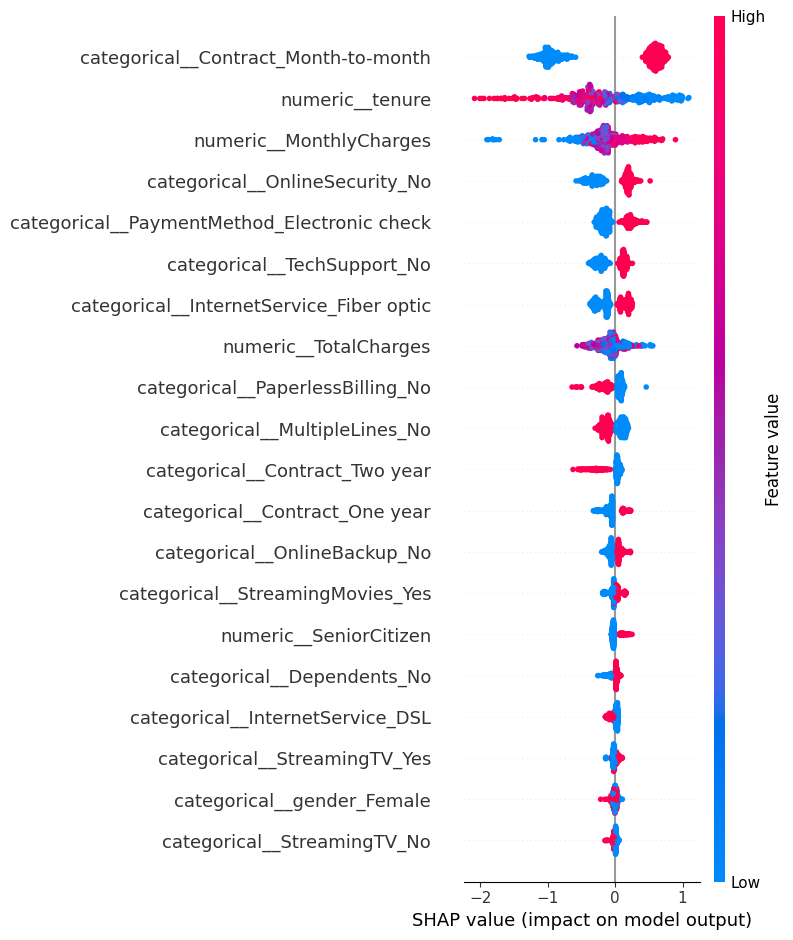

In [24]:
shap.summary_plot(
    shap_values,
    X_shap_dense,
    feature_names=feature_names,
    show=False,
)
plt.tight_layout()
plt.show()

Actual outcome (1 = churn): 0
Predicted churn probability: 0.015
Predicted outcome at threshold 0.45: 0


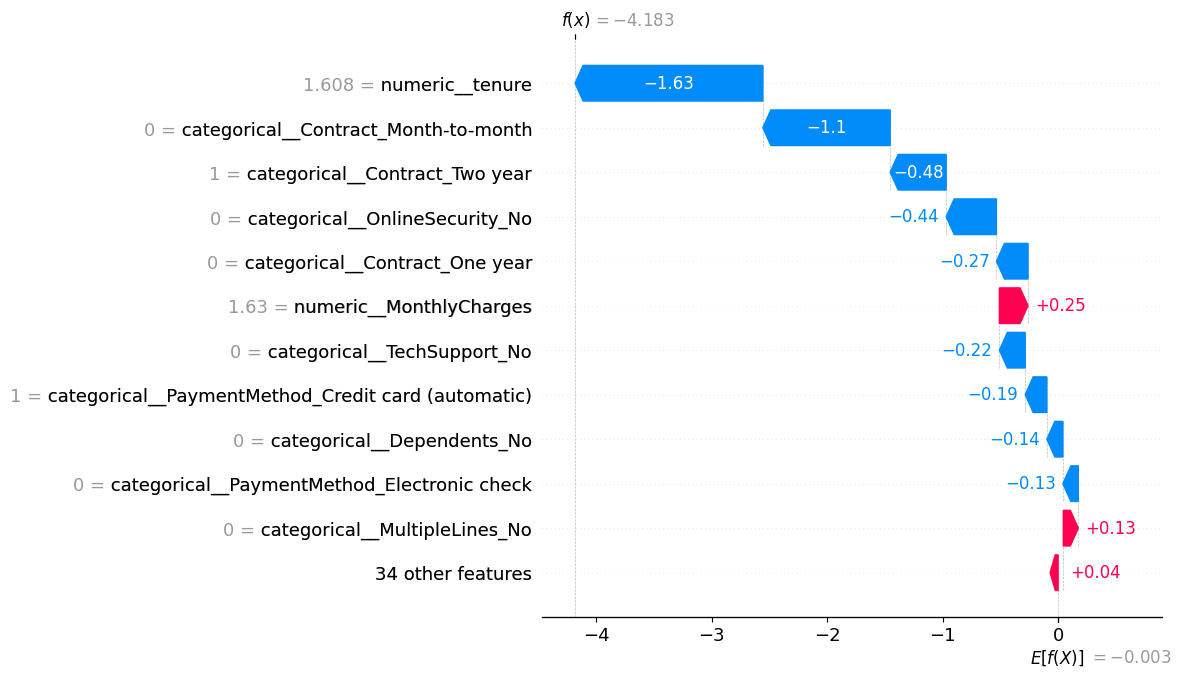

In [25]:
# Select one held-out customer.
customer = X_test.iloc[[0]]
actual_churn = int(y_test.iloc[0])

# Get the probability and classification at our chosen threshold.
customer_probability = final_model.predict_proba(customer)[0, 1]
customer_prediction = int(customer_probability >= chosen_threshold)

# Transform the customer using the already-fitted preprocessing steps.
customer_transformed = fitted_preprocessor.transform(customer)

if hasattr(customer_transformed, "toarray"):
    customer_transformed = customer_transformed.toarray()

# Calculate that customer's SHAP contributions with XGBoost.
customer_contributions = booster.predict(
    xgb.DMatrix(customer_transformed),
    pred_contribs=True,
)[0]

customer_shap_values = customer_contributions[:-1]
customer_base_value = customer_contributions[-1]

print("Actual outcome (1 = churn):", actual_churn)
print("Predicted churn probability:", round(customer_probability, 3))
print("Predicted outcome at threshold 0.45:", customer_prediction)

# Red features push the model output up; blue features push it down.
local_explanation = shap.Explanation(
    values=customer_shap_values,
    base_values=customer_base_value,
    data=customer_transformed[0],
    feature_names=feature_names,
)

shap.plots.waterfall(local_explanation, max_display=12)

In [26]:
from pathlib import Path
import joblib

models_folder = Path("../models")
models_folder.mkdir(exist_ok=True)

model_path = models_folder / "churn_pipeline.joblib"

# Save the complete pipeline plus the decision threshold and actual test metrics.
model_bundle = {
    "pipeline": final_model,
    "threshold": chosen_threshold,
    "model_name": "XGBoost",
    "test_metrics": {
        "precision": 0.502,
        "recall": 0.816,
        "f1": 0.621,
        "roc_auc": 0.843,
        "pr_auc": 0.661,
    },
}

joblib.dump(model_bundle, model_path)
print("Saved model bundle to:", model_path.resolve())

Saved model bundle to: C:\Users\Ramesh\OneDrive\Pictures\Desktop\Documents\Churn Prediction ML App\churn-prediction-app\models\churn_pipeline.joblib


In [27]:
loaded_bundle = joblib.load(model_path)

loaded_pipeline = loaded_bundle["pipeline"]
loaded_threshold = loaded_bundle["threshold"]

sample_customer = X_test.iloc[[0]]
sample_probability = loaded_pipeline.predict_proba(sample_customer)[0, 1]
sample_prediction = int(sample_probability >= loaded_threshold)

print("Loaded model:", loaded_bundle["model_name"])
print("Loaded threshold:", loaded_threshold)
print("Churn probability:", round(sample_probability, 3))
print("Predicted outcome (1 = churn):", sample_prediction)


Loaded model: XGBoost
Loaded threshold: 0.45
Churn probability: 0.015
Predicted outcome (1 = churn): 0
